# ToolNode와 tools_condition

**이 노트북에서 할 일**

1. 모델 노드와 도구 실행 노드(`ToolNode`)를 한 그래프에 넣고, 도구 조건 함수(`tools_condition`)로 잇습니다.
2. 규정을 찾아야 하는 질문과 인사 질문을 보내, 그래프가 어느 쪽으로 가는지 봅니다.
3. 규정 두 가지를 묻는 질문으로 바꿔, 그래프가 도구 쪽을 몇 번 다녀오는지 셉니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 6번입니다.
7절에서 2번, 8절에서 1번, 9절에서 3번을 보냈습니다.
모델이 도구를 몇 번 부르느냐에 따라 요청 수가 달라질 수 있습니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 노트북 안 규정 딕셔너리를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
Ch 19 함수 둘은 도구 파일 `graph_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.
모델 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langgraph 1.2.11, langchain 1.4.0, langchain-core 1.6.2입니다.
langchain-openai 1.6.0과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
도구와 상태 형식과 두 노드를 만들고, 그래프를 조립해 첫 질문을 보내는 자리입니다.
8~10절은 질문을 바꿔 보내고 세 질문을 견주는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch20-tool-node`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 맨 위 회색 가상 시작점 START에서 파란 상자 모델 노드 model 함수 call_model로 화살표가 가고, 모델 노드에서 점선 두 갈래가 나갑니다. 한 갈래는 도구 호출 요청 있음 이름표 tools를 달고 회색 상자 도구 실행 노드 tools ToolNode로, 다른 갈래는 도구 호출 요청 없음 이름표 END를 달고 회색 가상 끝점 END로 갑니다. 도구 실행 노드에서 모델 노드로 되돌아가는 엣지라고 적힌 실선 화살표가 올라가는 그림](attachment:01-1-모델과-도구를-오가는-그래프.png)

위에서 아래로 읽고, 상자 넷은 노트북 6절 구조 문자열의 상자 넷과 같습니다.
파란 상자는 우리가 적은 모델 노드, 회색 상자는 LangGraph가 준 도구 실행 노드와 가상 시작점·끝점입니다.
모델 노드에서 나가는 점선 두 갈래는 도구 조건 함수가 고르고, 이 함수는 노드가 아니라 상자로 그리지 않았습니다.
도구 실행 노드에서 모델 노드로 올라가는 실선이 되돌아가는 엣지입니다.
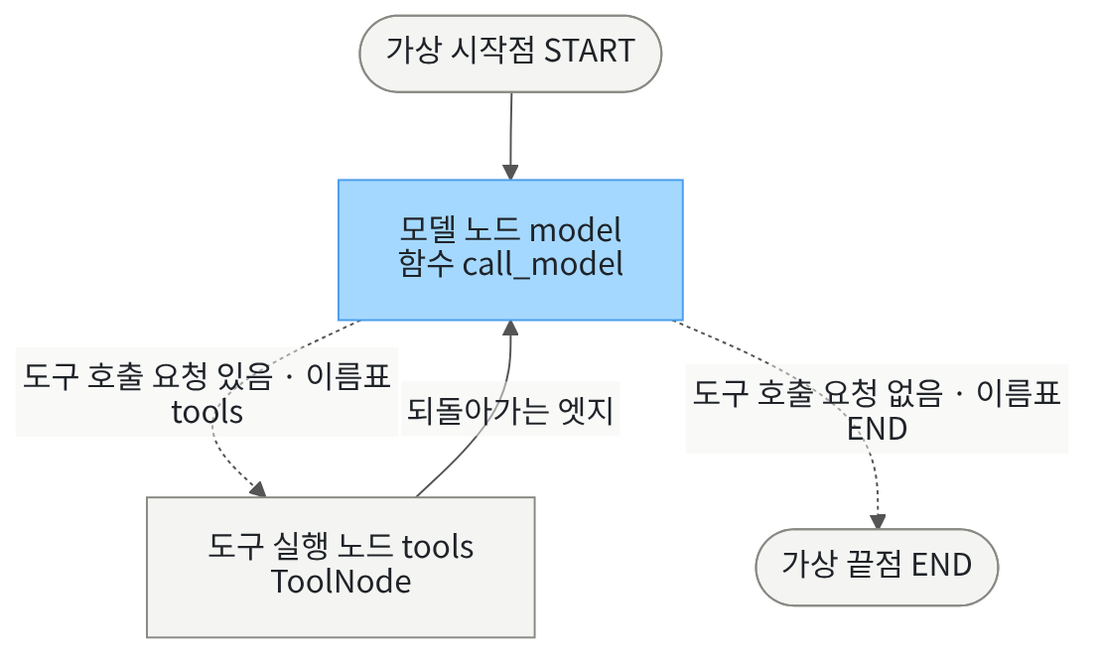

## 1. 준비

Ch 19 05절에서는 도구 호출 요청을 실행하고 다시 묻는 일을 우리가 쓴 함수 `ask_until_answer`가 했습니다.
이 절에서는 같은 일을 Ch 13의 상태 그래프가 맡습니다.
제목의 `ToolNode`는 도구 실행 노드, `tools_condition`은 도구 조건 함수이고, 뜻은 5절에서 풉니다.

첫 셀은 패키지 다섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`·`langchain: 1.4.0`·`langchain-core: 1.6.2`가 보입니다.
출력 줄 `langchain-openai: 1.6.0`과 `python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식·메시지·그래프 이름은 Ch 13 04절, 모델과 `tool`은 Ch 19에서 쓴 이름입니다.
새 이름은 모듈 `langgraph.prebuilt`에서 가져오는 `ToolNode`와 `tools_condition` 둘입니다.
도구 파일에서는 Ch 19 함수 `show_messages`와 `tool_call_names`를 가져옵니다.

In [2]:
# Ch 13 그래프 이름과 Ch 19 도구 이름에, 이 절의 새 이름 둘과 도구 파일 함수 둘을 더해 가져옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict

from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, AnyMessage, HumanMessage
from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
# 도구 실행 노드와 도구 조건 함수는 LangGraph가 미리 만들어 둔 부품입니다
from langgraph.prebuilt import ToolNode, tools_condition

from graph_tools import show_messages, tool_call_names

print("이 절에서 새로 가져온 이름:", "ToolNode", "tools_condition")

이 절에서 새로 가져온 이름: ToolNode tools_condition


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: ToolNode tools_condition`이 보입니다.
모듈 `langgraph.prebuilt`는 LangGraph가 미리 만들어 둔 부품을 모아 둔 곳입니다.

앞에서 배운 함수는 `graph_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

이 파일은 Ch 19 도구 파일 `order_tools.py`와 다른 파일입니다.
이 챕터 노트북이 쓰는 Ch 19 함수만 본문을 글자 그대로 옮겼습니다.
함수 `tool_call_names`는 Ch 19 04절, 함수 `show_messages`는 Ch 19 06절에서 배웠습니다.
이 절에서 만드는 함수 `call_id_lists`·`run_row`도 뒤 절이 쓰도록, 본문을 글자 그대로 이 파일에 옮겨 두었습니다.

## 2. 키와 모델 준비

모델은 Ch 19와 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 도구 호출 요청을 보낼지가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 규정 자료와 도구

이 챕터는 교육센터 자료실 규정을 소재로 씁니다.
규정은 대출·운영·연체 세 가지이고, 노트북 안 딕셔너리에 적어 둡니다.
다음 셀은 주제어를 키, 규정 글을 값으로 둔 딕셔너리를 만듭니다.

In [5]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
도구는 이 딕셔너리를 읽기만 하고 바꾸지 않으므로, Ch 19 06절 말로 읽기 도구입니다.

다음 셀은 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다.
맨 `@tool` 줄과 독스트링, 매개변수의 `: str` 표시는 Ch 19 01절에서 배운 모양입니다.
딕셔너리에 없는 주제어면 Ch 16 01절처럼 `raise`로 오류를 냅니다.
이 오류를 그래프 안에서 어떻게 다루는지는 02절에서 봅니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(이 오류를 다루는 법은 02절에서 봅니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
독스트링은 도구 설명이 되어 모델 요청에 실립니다.
설명에 주제어 셋을 적어, 모델이 인자에 무엇을 넣을지 알게 했습니다.

다음 셀은 모델 없이 도구를 한 번 불러 봅니다.
Ch 19 01절처럼 메서드 `.invoke`에 인자 딕셔너리를 넣습니다.

In [7]:
# 모델 없이 도구를 인자 딕셔너리로 한 번 불러 봅니다(Ch 19 01절처럼 .invoke)
print("도구 이름:", lookup_policy.name)
print("입력 형식:", lookup_policy.args)
loan_policy = lookup_policy.invoke({"topic": "대출"})
print("대출 규정:", loan_policy)

도구 이름: lookup_policy
입력 형식: {'topic': {'title': 'Topic', 'type': 'string'}}
대출 규정: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.


**결과 읽기** — 출력 줄 `도구 이름: lookup_policy`는 함수 이름에서 왔습니다.
라벨 `입력 형식:` 뒤 딕셔너리에서 인자 `topic`의 자료형은 `string`입니다.
출력 줄 `대출 규정: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.`로 도구가 규정 글을 내놓았습니다.

다음 셀은 도구 목록을 메서드 `bind_tools`로 모델에게 알려 줍니다.
인자 `parallel_tool_calls=False`는 한 응답에 도구 호출 요청을 하나까지만 받게 합니다.
Ch 19 06절과 같은 값이고, 규정을 둘 찾아야 할 때의 흐름은 9절에서 봅니다.

In [8]:
# 도구 목록을 모델에게 알려 줍니다(Ch 19 04절 bind_tools, 요청은 아직 보내지 않음)
tools = [lookup_policy]
# 한 응답에 도구 호출 요청을 하나까지만 받게 합니다(Ch 19 06절과 같은 값)
bound_model = model.bind_tools(tools, parallel_tool_calls=False)
print("실어 보낼 명세 수:", len(bound_model.kwargs["tools"]))
print("여럿 담기:", bound_model.kwargs["parallel_tool_calls"])

실어 보낼 명세 수: 1
여럿 담기: False


**결과 읽기** — 출력 줄 `실어 보낼 명세 수: 1`은 도구 하나의 명세가 요청마다 실린다는 뜻입니다.
출력 줄 `여럿 담기: False`처럼 여럿 담기를 끈 값도 함께 실립니다.
아직 모델 요청은 보내지 않았습니다.

## 4. 상태 형식과 모델 노드

그래프에 넣을 상태 형식을 정합니다.
메시지 칸에는 Ch 13 04절처럼 메시지 리듀서 `add_messages`를 적습니다.
실행 흔적 칸에는 Ch 13 02절처럼 이어 붙이기 규칙 `operator.add`를 적습니다.
두 칸 모두 규칙이 있으므로, 노드는 자기 몫만 내면 됩니다.
칸 구성이 Ch 13 04절 `ChatState`와 달라서 새 이름 `AgentState`를 붙입니다.

In [9]:
# 메시지 칸과 실행 흔적 칸에 각각 규칙을 적은 상태 형식을 만듭니다(Ch 13 04절 모양)
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메시지 칸 `messages`에는 질문·응답·도구 메시지가 차례로 쌓입니다.
실행 흔적 칸 `trace`에는 노드가 낸 이름이 뒤에 붙습니다.

다음 셀은 모델 노드 함수입니다.
모델 노드는 메시지 칸 전체를 모델에 보내고, 받은 응답을 메시지 칸에 더하는 노드입니다.
함수는 응답 하나와 노드 이름 `"model"`만 담은 딕셔너리를 냅니다.
그래프는 노드 함수에 상태 하나만 넘기므로, 모델은 앞 셀의 `bound_model`을 그대로 씁니다.

In [10]:
# 메시지 칸 전체를 도구를 알려 준 모델에 보내고, 응답 하나와 노드 이름만 냅니다
def call_model(state):
    response = bound_model.invoke(state["messages"])
    return {"messages": [response], "trace": ["model"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드를 한 번 지날 때마다 모델 요청이 한 번 나갑니다.
그래서 실행 흔적 칸에 붙은 `model`의 수가 곧 모델 요청 수입니다.

## 5. 도구 실행 노드와 도구 조건 함수

Ch 19 05절에서는 도구 호출 요청을 우리가 쓴 함수 `run_tool_calls`로 실행했습니다.
이 절에서는 그 일을 LangGraph가 미리 만들어 둔 노드가 맡습니다.
도구 실행 노드(`ToolNode`)는 마지막 응답의 도구 호출 요청을 실행하는 노드입니다.
실행 결과는 도구 메시지로 만들어 메시지 칸에 더합니다.
다음 셀은 도구 목록으로 도구 실행 노드를 만듭니다.

In [11]:
# 도구 목록으로 도구 실행 노드를 만듭니다(아직 그래프에 넣지 않음)
tool_node = ToolNode(tools)
print("만든 것의 종류:", type(tool_node).__name__)
# 속성 tools_by_name은 Ch 19 05절의 도구 찾기 표와 같은 모양입니다
table_keys = list(tool_node.tools_by_name.keys())
print("안에 든 도구 찾기 표의 키:", table_keys)

만든 것의 종류: ToolNode
안에 든 도구 찾기 표의 키: ['lookup_policy']


**결과 읽기** — 출력 줄 `만든 것의 종류: ToolNode`입니다.
출력 줄 `안에 든 도구 찾기 표의 키: ['lookup_policy']`처럼, 노드 안에 도구 찾기 표가 들어 있습니다.
Ch 19 05절에서 우리가 만든 표 `tools_by_name`과 같은 모양입니다.

다음은 조건부 엣지에 넣을 조건 함수입니다.
도구 조건 함수(`tools_condition`)는 LangGraph가 미리 만들어 둔 조건 함수입니다.
마지막 응답에 도구 호출 요청이 있으면 이름표 `"tools"`를, 없으면 가상 끝점 `END`를 내놓습니다.
Ch 13 03절 조건 함수처럼 노드로 등록하지 않고 조건부 엣지에 넣습니다.

그래프 없이 이 함수를 불러 보려고, 다음 셀은 응답 두 개를 손으로 만듭니다.
Ch 13 04절처럼 `AIMessage`를 직접 만들고, 둘째 응답에만 도구 호출 요청을 넣습니다.

In [12]:
# 모델을 부르지 않고, 도구 조건 함수에 넣어 볼 응답 두 개를 손으로 만듭니다
plain_answer = AIMessage(content="규정을 찾지 않고 바로 답합니다.")
# 둘째 응답에는 Ch 19 04절의 칸 넷을 담은 도구 호출 요청 하나를 넣습니다
hand_call = {"name": "lookup_policy", "args": {"topic": "대출"}, "id": "hand_call_1", "type": "tool_call"}
hand_request = AIMessage(content="", tool_calls=[hand_call])
print("첫 응답의 도구 호출 요청:", tool_call_names(plain_answer))
print("둘째 응답의 도구 호출 요청:", tool_call_names(hand_request))

첫 응답의 도구 호출 요청: []
둘째 응답의 도구 호출 요청: ['lookup_policy']


**결과 읽기** — 출력 줄 `첫 응답의 도구 호출 요청: []`은 요청이 없는 응답이라는 뜻입니다.
출력 줄 `둘째 응답의 도구 호출 요청: ['lookup_policy']`는 요청 하나를 담은 응답입니다.
두 응답은 우리가 손으로 만든 것이고, 모델이 쓴 응답이 아닙니다.

다음 셀은 도구 조건 함수에 두 응답을 하나씩 넣어, 내놓는 이름표를 봅니다.
그래프의 상태처럼 키 `messages`에 메시지 목록을 담아 넘깁니다.

In [13]:
# 도구 조건 함수를 그래프 없이 직접 불러, 두 응답에 어떤 이름표를 내놓는지 봅니다
plain_label = tools_condition({"messages": [plain_answer]})
request_label = tools_condition({"messages": [hand_request]})
print("요청이 없는 응답의 이름표:", plain_label)
print("요청이 있는 응답의 이름표:", request_label)
print("END와 같은가:", plain_label == END)

요청이 없는 응답의 이름표: __end__
요청이 있는 응답의 이름표: tools
END와 같은가: True


**결과 읽기** — 출력 줄 `요청이 없는 응답의 이름표: __end__`입니다.
출력 줄 `요청이 있는 응답의 이름표: tools`입니다.
출력 줄 `END와 같은가: True`로, 글자 `__end__`가 가상 끝점 `END`의 값임을 확인합니다.
이 함수는 질문의 낱말이나 답의 내용은 보지 않고, 마지막 응답의 도구 호출 요청이 있는지만 봅니다.
설치한 langgraph-prebuilt 1.1.0 소스도 요청의 개수가 0보다 큰지만 봅니다.

다음 셀은 두 이름표를 실제로 갈 곳에 잇는 이름표 표(`path_map`)를 만듭니다.
Ch 13 03절처럼 딕셔너리로 적고, 끝 쪽에는 글자 대신 상수 `END`를 씁니다.

In [14]:
# 도구 조건 함수의 이름표 둘을 실제로 갈 곳에 잇는 이름표 표를 만듭니다(Ch 13 03절)
path_map = {"tools": "tools", END: END}
print("이름표와 갈 곳을 이은 표:")
for label in path_map:
    print(label, "->", path_map[label])

이름표와 갈 곳을 이은 표:
tools -> tools
__end__ -> __end__


**결과 읽기** — 라벨 줄 `이름표와 갈 곳을 이은 표:` 아래 두 줄입니다.
출력 줄 `tools -> tools`는 이름표 `"tools"`가 오면 이름이 `tools`인 노드로 간다는 뜻입니다.
출력 줄 `__end__ -> __end__`는 `END`가 오면 가상 끝점으로 가서 끝난다는 뜻입니다.
그래서 도구 실행 노드는 다음 셀에서 이름 `"tools"`로 등록합니다.

## 6. 그래프 조립과 되돌아가는 엣지

다음 셀은 설계 객체를 만들고 노드 둘을 등록합니다.
모델 노드는 이름 `"model"`, 도구 실행 노드는 이름 `"tools"`입니다.

In [15]:
# 설계 객체를 만들고 모델 노드와 도구 실행 노드를 등록합니다
builder = StateGraph(AgentState)
builder.add_node("model", call_model)
builder.add_node("tools", tool_node)
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['model', 'tools']


**결과 읽기** — 출력 줄 `등록한 노드: ['model', 'tools']`입니다.
도구 조건 함수는 노드가 아니므로 이 목록에 없습니다.

다음 셀은 엣지 셋을 적고 컴파일합니다.
시작 엣지와 조건부 엣지는 Ch 13 01·03절에서 배운 모양입니다.
셋째 줄 `builder.add_edge("tools", "model")`은 이 과정에서 처음 보는 모양입니다.
지금까지 엣지는 앞 노드에서 뒤 노드로만 갔습니다.
이 엣지는 뒤에 있는 도구 실행 노드에서 앞의 모델 노드로 되돌아가, 모델 노드를 다시 지나게 합니다.

In [16]:
# 시작 엣지, 조건부 엣지, 되돌아가는 엣지를 적고 컴파일합니다
builder.add_edge(START, "model")
builder.add_conditional_edges("model", tools_condition, path_map)
# 도구 실행 노드가 끝나면 앞에 있는 모델 노드로 다시 갑니다
builder.add_edge("tools", "model")
graph = builder.compile()
print("고정 엣지로 적은 수:", len(builder.edges))
print("컴파일 결과의 종류:", type(graph).__name__)

고정 엣지로 적은 수: 2
컴파일 결과의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 2`는 시작 엣지와 셋째 줄 엣지입니다.
조건부 엣지는 이 수에 들어가지 않고 따로 적힙니다.
출력 줄 `컴파일 결과의 종류: CompiledStateGraph`로 컴파일이 끝났습니다.
셋째 줄 엣지처럼 뒤 노드에서 앞 노드로 다시 가는 엣지를, 이 절에서는 되돌아가는 엣지라고 부릅니다.

다음 셀은 Ch 13 01절처럼 그래프가 스스로 그린 구조 문자열을 받아 옵니다.

In [17]:
# 컴파일한 그래프가 스스로 그린 구조 문자열을 받아 옵니다(Ch 13 01절)
structure_text = graph.get_graph().draw_mermaid()
print("그래프가 그린 구조:")
print(structure_text)

그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools --> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 라벨 줄 `그래프가 그린 구조:` 아래에서 화살표 줄 넷을 봅니다.
줄 `model -.-> __end__`와 `model -.-> tools`는 조건부 엣지의 두 갈래라 점선입니다.
줄 `tools --> model`이 되돌아가는 엣지이고, 실선입니다.
도구 조건 함수는 상자가 아니라 모델 노드에서 나가는 점선 두 줄로만 나타납니다.

## 7. 도구가 필요한 질문

첫 질문은 자료실 규정을 찾아야 답할 수 있는 질문입니다.
상태에는 메시지 칸에 질문 하나, 실행 흔적 칸에 빈 목록을 넣습니다.
실행 전에 예상해 봅니다.
모델이 대출 규정을 찾는 요청을 보내면, 흐름은 모델 노드 → 도구 실행 노드 → 모델 노드일 것입니다.

In [18]:
# 규정을 찾아야 답할 수 있는 질문으로 그래프를 실행합니다(모델 노드를 지날 때마다 모델 요청 1번)
loan_question = "자료실에서 일반 도서를 며칠 빌릴 수 있나요?"
loan_state = {"messages": [HumanMessage(content=loan_question)], "trace": []}
loan_result = graph.invoke(loan_state)
print("실행 흔적 칸:", loan_result["trace"])
print("메시지 칸의 메시지 수:", len(loan_result["messages"]))

실행 흔적 칸: ['model', 'model']
메시지 칸의 메시지 수: 4


**결과 읽기** — 출력 줄 `실행 흔적 칸: ['model', 'model']`로 모델 노드를 두 번 지났습니다.
그래서 이 질문의 모델 요청은 2번입니다.
출력 줄 `메시지 칸의 메시지 수: 4`입니다.
도구 실행 노드는 실행 흔적 칸을 쓰지 않으므로, 도구 실행은 메시지 칸에서 봅니다.

다음 셀은 Ch 19 06절 함수 `show_messages`로 메시지 칸을 차례로 출력합니다.

In [19]:
# 메시지 칸을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("메시지 칸:")
show_messages(loan_result["messages"])

메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 `메시지 칸:` 아래 네 줄이 메시지 칸의 차례입니다.
질문 다음 줄은 `AIMessage | 도구 호출 요청: ['lookup_policy']`입니다.
셋째 줄 도구 메시지는 결과 상태가 `success`이고, 내용은 대출 규정 글입니다.
넷째 줄 `AIMessage | 도구 호출 요청: []`는 요청이 없는 응답이라, 도구 조건 함수가 `END`로 보냈습니다.
도구 메시지가 더해진 뒤 되돌아가는 엣지로 모델 노드에 다시 간 것입니다.

다음 셀은 첫 응답에 담긴 도구 호출 요청의 이름과 인자를 봅니다.

In [20]:
# 둘째 메시지(첫 응답)에 담긴 도구 호출 요청의 이름과 인자를 봅니다
first_response = loan_result["messages"][1]
for call in first_response.tool_calls:
    print("도구 이름:", call["name"], "| 인자:", call["args"])

도구 이름: lookup_policy | 인자: {'topic': '대출'}


**결과 읽기** — 출력 줄 `도구 이름: lookup_policy | 인자: {'topic': '대출'}`입니다.
모델이 질문을 읽고 주제어 `대출`을 골라 인자에 넣었습니다.
도구를 부를지와 인자는 모델이 정했고, 도구를 실행한 것은 도구 실행 노드입니다.

다음 셀은 메시지 목록에서 요청 id 목록과 호출 ID 목록을 모으는 함수입니다.
호출 ID는 Ch 19 05절에서 본, 도구 메시지가 어느 요청의 결과인지 알리는 번호입니다.
Ch 19 05절은 이 짝을 셀 안에서 견줬고, 여기서는 세 질문에 쓰려고 함수로 만듭니다.

In [21]:
# 메시지 목록에서 도구 호출 요청의 id 목록과 도구 메시지의 호출 ID 목록을 모아 내놓습니다
def call_id_lists(messages):
    lists = {"요청 id": [], "호출 ID": []}
    for message in messages:
        if type(message).__name__ == "AIMessage":
            for call in message.tool_calls:
                lists["요청 id"].append(call["id"])
        if type(message).__name__ == "ToolMessage":
            lists["호출 ID"].append(message.tool_call_id)
    return lists

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `call_id_lists`는 키 둘(`요청 id`·`호출 ID`)에 목록을 담은 딕셔너리를 내놓습니다.
응답이면 도구 호출 요청마다 칸 `id`를, 도구 메시지면 칸 `tool_call_id`를 모읍니다.

다음 셀은 대출 질문 흐름에서 두 목록의 짝이 맞는지 봅니다.
이 목록은 도구 실행 노드가 옮겨 적은 값이라, 모델이 요청을 몇 건 보내든 짝이 맞아야 합니다.
그래서 셀 끝에서 `assert`로 확인합니다.

In [22]:
# 대출 질문 흐름에서 요청 id 목록과 호출 ID 목록이 같은 차례로 짝이 맞는지 봅니다
loan_ids = call_id_lists(loan_result["messages"])
print("요청 id 수:", len(loan_ids["요청 id"]))
print("호출 ID 수:", len(loan_ids["호출 ID"]))
print("짝이 맞는가:", loan_ids["요청 id"] == loan_ids["호출 ID"])
# 도구 실행 노드가 옮겨 적는 값이라 매번 같아야 합니다
assert loan_ids["요청 id"] == loan_ids["호출 ID"], "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"

요청 id 수: 1
호출 ID 수: 1
짝이 맞는가: True


**결과 읽기** — 출력 줄 `요청 id 수: 1`과 `호출 ID 수: 1`입니다.
출력 줄 `짝이 맞는가: True`로, 도구 실행 노드가 요청 `id`를 도구 메시지에 옮겨 적었습니다.
Ch 19 05절에서 우리가 도구에 요청을 통째로 넣어 하던 일과 같습니다.
칸 `id`의 값은 요청마다 새로 붙어 실행마다 다르므로, 여기에 옮겨 적지 않습니다.

다음 셀은 메시지 칸의 마지막 응답을 봅니다.

In [23]:
# 메시지 칸의 마지막 응답을 봅니다(도구 호출 요청 수와 답 글)
last_message = loan_result["messages"][-1]
print("마지막 응답의 도구 호출 요청 수:", len(last_message.tool_calls))
print("답 글:")
print(last_message.content)

마지막 응답의 도구 호출 요청 수: 0
답 글:
자료실의 일반 도서는 **1인 5권까지 14일 동안** 빌릴 수 있습니다.


**결과 읽기** — 출력 줄 `마지막 응답의 도구 호출 요청 수: 0`입니다.
라벨 줄 `답 글:` 아래가 모델이 도구 메시지를 읽고 쓴 최종 답입니다.

답 글의 문장은 실행마다 달라질 수 있어, 결론에 쓰지 않습니다.
이번 실행에서는 답 글에 도구 메시지의 `5권`과 `14일`이 들어 있었습니다.
답 글의 별표 두 개(`**`)는 모델이 굵은 글씨를 표시하려고 붙인 기호입니다.

## 8. 도구가 필요 없는 질문

둘째 질문은 규정을 찾을 까닭이 없는 인사입니다.
같은 그래프에 질문만 바꿔 넣습니다.
실행 전에 예상해 봅니다.
모델이 도구 호출 요청 없이 바로 답하면, 흐름은 모델 노드 한 번으로 끝날 것입니다.

In [24]:
# 규정을 찾을 까닭이 없는 인사 질문으로 같은 그래프를 실행합니다(모델 요청 1번 예상)
greet_question = "안녕하세요. 한 문장으로 인사해 주세요."
greet_state = {"messages": [HumanMessage(content=greet_question)], "trace": []}
greet_result = graph.invoke(greet_state)
print("실행 흔적 칸:", greet_result["trace"])
print("메시지 칸:")
show_messages(greet_result["messages"])
print("답 글:", greet_result["messages"][-1].content)

실행 흔적 칸: ['model']
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: []
답 글: 안녕하세요, 반갑습니다!


**결과 읽기** — 출력 줄 `실행 흔적 칸: ['model']`로 모델 노드를 한 번만 지났습니다.
라벨 줄 `메시지 칸:` 아래는 `HumanMessage`와 `AIMessage | 도구 호출 요청: []` 두 줄입니다.
첫 응답에 요청이 없어, 도구 조건 함수가 바로 `END`로 보냈습니다.
도구 실행 노드는 한 번도 실행되지 않았고, 모델 요청은 1번입니다.

답 글은 실행마다 달라질 수 있습니다.
이번 실행에서는 `안녕하세요, 반갑습니다!`였습니다.
노트북 밖에서 이 질문을 다섯 번 보냈을 때도 다섯 번 모두 도구 호출 요청이 없었습니다.
답 글은 문장부호만 조금씩 달랐습니다.

## 9. 값 바꿔 보기 · 규정 두 가지를 묻는 질문

바꿀 값은 질문 하나입니다.
운영 시간과 연체 규정을 함께 묻는, 규정 두 가지가 필요한 질문으로 바꿉니다.
그래프와 도구, 여럿 담기를 끈 설정은 그대로입니다.
실행 전에 예상해 봅니다.
응답마다 요청이 하나까지만 오므로, 도구 쪽을 두 번 다녀오고 모델 요청은 3번일 것입니다.

In [25]:
# 바꿀 값: 질문 하나만, 규정 두 가지가 필요한 질문으로 바꿔 같은 그래프를 실행합니다
two_question = "자료실 운영 시간과 연체 규정을 함께 알려 주세요."
two_state = {"messages": [HumanMessage(content=two_question)], "trace": []}
two_result = graph.invoke(two_state)
print("실행 흔적 칸:", two_result["trace"])
print("메시지 칸:")
show_messages(two_result["messages"])

실행 흔적 칸: ['model', 'model', 'model']
메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 연체한 일수만큼 새 대출이 제한됩니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `실행 흔적 칸: ['model', 'model', 'model']`로 모델 노드를 세 번 지났습니다.
라벨 줄 `메시지 칸:` 아래 여섯 줄에서 응답과 도구 메시지가 번갈아 나옵니다.
도구 메시지 둘은 모두 결과 상태가 `success`입니다.
되돌아가는 엣지를 두 번 지났고, 모델 요청이 세 번이라 Ch 19 05절 말로 바퀴가 세 번 돌았습니다.

다음 셀은 응답마다 도구 호출 요청 수와 인자를 보고, 호출 ID 짝을 셉니다.

In [26]:
# 응답마다 도구 호출 요청 수와 인자를 차례로 보고, 호출 ID 짝을 셉니다
for message in two_result["messages"]:
    if type(message).__name__ == "AIMessage":
        print("응답 | 도구 호출 요청 수:", len(message.tool_calls))
        for call in message.tool_calls:
            print("  인자:", call["args"])
two_ids = call_id_lists(two_result["messages"])
print("호출 ID 짝이 맞는가:", two_ids["요청 id"] == two_ids["호출 ID"])

응답 | 도구 호출 요청 수: 1
  인자: {'topic': '운영'}
응답 | 도구 호출 요청 수: 1
  인자: {'topic': '연체'}
응답 | 도구 호출 요청 수: 0
호출 ID 짝이 맞는가: True


**결과 읽기** — 첫 응답은 요청 한 건이고, 인자는 `{'topic': '운영'}`입니다.
둘째 응답도 한 건이고, 인자는 `{'topic': '연체'}`입니다.
셋째 응답은 `응답 | 도구 호출 요청 수: 0`이라 최종 답입니다.
출력 줄 `호출 ID 짝이 맞는가: True`로, 두 도구 메시지 모두 짝이 맞았습니다.

Ch 19 05절 하나씩 흐름처럼, 요청이 응답마다 한 건씩 나뉘어 왔습니다.
그때는 바퀴 한도 `turn_limit`를 둔 `for` 루프가 되풀이를 맡았습니다.
이 그래프에는 그런 `for`가 없고, 도구 조건 함수가 `END`를 고를 때까지 그래프가 스스로 되풀이합니다.
그래프가 되풀이하는 횟수에도 한도가 있고, 그 한도는 03절에서 다룹니다.

## 10. 세 질문 견주기

다음 셀은 실행 결과 하나를 기록 한 줄로 만드는 함수입니다.
모델 요청 수는 실행 흔적 칸의 길이로, 도구 메시지 수는 호출 ID 목록의 길이로 셉니다.

In [27]:
# 실행 결과 하나를 기록 한 줄로 만듭니다(모델 요청 수 = 실행 흔적 칸의 길이)
def run_row(question_name, result):
    ids = call_id_lists(result["messages"])
    row = {"질문": question_name}
    row["실행 흔적"] = result["trace"]
    row["모델 요청 수"] = len(result["trace"])
    row["도구 메시지 수"] = len(ids["호출 ID"])
    row["호출 ID 짝"] = ids["요청 id"] == ids["호출 ID"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_row`는 칸 다섯을 담은 딕셔너리를 내놓습니다.
칸은 질문·실행 흔적·모델 요청 수·도구 메시지 수·호출 ID 짝입니다.

다음 셀은 세 질문의 기록을 모아 한 줄씩 출력합니다.

In [28]:
# 세 질문의 기록을 모아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("대출 질문", loan_result))
run_rows.append(run_row("인사 질문", greet_result))
run_rows.append(run_row("운영·연체 질문", two_result))
print("질문 | 실행 흔적 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝")
for row in run_rows:
    print(row["질문"], "|", row["실행 흔적"], "|", row["모델 요청 수"], "|", row["도구 메시지 수"], "|", row["호출 ID 짝"])

질문 | 실행 흔적 | 모델 요청 수 | 도구 메시지 수 | 호출 ID 짝
대출 질문 | ['model', 'model'] | 2 | 1 | True
인사 질문 | ['model'] | 1 | 0 | True
운영·연체 질문 | ['model', 'model', 'model'] | 3 | 2 | True


**결과 읽기** — 라벨 줄 아래 세 줄입니다.
대출 질문은 `대출 질문 | ['model', 'model'] | 2 | 1 | True`입니다.
인사 질문은 `인사 질문 | ['model'] | 1 | 0 | True`입니다.
바꾼 질문은 `운영·연체 질문 | ['model', 'model', 'model'] | 3 | 2 | True`입니다.

인사 질문의 짝 `True`는 요청 id 목록과 호출 ID 목록이 모두 비어 있어 나온 값입니다.
세 질문 모두 모델 요청 수가 도구 메시지 수보다 하나 많았습니다.
여럿 담기를 꺼서, 도구 호출 요청이 있는 응답마다 도구 메시지가 하나였습니다.
마지막 응답은 늘 도구 호출 요청이 없는 응답이라, 그 요청 한 번만큼 많습니다.

세 흐름은 같은 그래프였고, 도구 쪽으로 몇 번 갈지는 모델의 응답이 정했습니다.
노트북 밖에서 세 질문을 다섯 번씩 보냈을 때도 세 줄의 값이 모두 같았습니다.

Ch 19 05절 함수 `ask_until_answer`의 줄마다 이 그래프에서 맡는 곳은 아래와 같습니다.

- 모델에게 묻는 줄 `bound_model.invoke(messages)`는 모델 노드 `call_model`이 맡습니다.
- 도구를 실행하는 함수 `run_tool_calls`는 도구 실행 노드 `ToolNode(tools)`가 맡습니다.
- 요청이 없으면 멈추는 `break`는 도구 조건 함수가 `END`를 내놓는 일이 맡습니다.
- 목록에 붙이는 `messages.append`는 메시지 칸의 메시지 리듀서 `add_messages`가 맡습니다.
- 되풀이하는 `for` 루프는 되돌아가는 엣지 `tools → model`이 맡고, 한도는 03절에서 봅니다.

## 정리

1. 도구 조건 함수는 마지막 응답에 도구 호출 요청이 있으면 도구 실행 노드로, 없으면 `END`로 보냈습니다.
2. 도구 실행 노드가 도구 메시지를 더하면, 되돌아가는 엣지로 모델 노드에 다시 갔습니다.
3. 대출·인사·운영과 연체 질문의 모델 요청은 2·1·3번, 도구 메시지는 1·0·2개였습니다.

02절에서는 도구 실행 노드가 실행한 도구가 오류를 낼 때를 봅니다.
Ch 19 06절에서 도구 속성으로 하던 일을 도구 실행 노드 쪽에서 다룹니다.